# ЛР 1. Начало работы с ML-проектом: формализация задачи и первичный анализ данных

**Датасет:** Dota 2 — классификация локации энергии Древних  
**Подгруппа:** МО-241  

## Содержание

1. [Постановка задачи и предметная область](#sec1)
2. [Описание признаков](#sec2)
3. [Фиксация виртуального окружения](#sec3)
4. [Загрузка данных и первичный осмотр](#sec4)
5. [Анализ природы признаков](#sec5)
6. [Диагностика пропусков](#sec6)
7. [Методы заполнения пропусков](#sec7)
8. [Корреляции и распределения по классам](#sec8)
9. [Приведение типов](#sec10)
10. [Разделение на train/test и применение заполнения](#sec10)
11. [Выводы по работе](#sec11)

<a id='sec1'></a>
## 1. Постановка задачи и предметная область

### Бизнес-контекст

По легенде заказчика (Invoker), в мир проникают микроскопические осколки двух враждующих сил — Radiant и Dire. Эти осколки меняют свойства материи, концентрируясь в различных слоях вещества: внешних, внутренних, промежуточных барьерах. Цель — научиться определять **где именно** сосредоточилась чужеродная энергия ещё до того, как её влияние станет заметным невооружённым глазом.

### Формализация ML-задачи

| Параметр | Значение |
|----------|----------|
| **Тип задачи** | Многоклассовая классификация (multiclass classification) |
| **Объект** | Образец вещества с обнаруженными признаками проникновения энергии |
| **Целевой признак** | `class` — локация концентрации осколков (8 категорий) |
| **Входные признаки** | 7 характеристик отклика на энергию Radiant/Dire, наличие меток, заряд эссенции, состав внутренней энергии, характер распространения |
| **Выход модели** | Предсказание локации концентрации (`inner_core`, `outer_layer`, `deep_barrier`, и др.) для нового образца |

### Особенности данных

- Малый объём выборки: **n = 336 наблюдений**.
- Сильная несбалансированность классов: доминирует `inner_core` (42.56%), три класса имеют ≤ 5 наблюдений (статистически ненадёжны).
- Присутствуют пропуски в 4 из 7 признаков (максимум 26.19%).
- Два признака имеют индикаторную природу (бинарные события), а не непрерывную.

<a id='sec2'></a>
## 2. Описание признаков

| Признак | Семантика | Тип данных |
|---------|------------------------|------------|
| `radiant_resonance` | Отклик вещества на энергию Radiant | float64 |
| `dire_resonance` | Отклик на энергию Dire | float64 |
| `arcane_mark` | Наличие особой магической метки | float64 |
| `energy_charge` | Заряд эссенции | float64 |
| `essence_composition` | Состав внутренней энергии | float64
| `outer_energy_flow` | Характер распространения по внешним слоям | float64 |
| `inner_energy_flow` | Характер распространения по внутренним слоям | float64 |
| `class` | Локация концентрации осколков | str |

### Классы целевого признака (по убыванию частоты)

| Класс | Доля | Кол-во | Надёжность статистики |
|-------|------|--------|----------------------|
| `inner_core` | 42.56% | 143 | Высокая |
| `inner_barrier` | 22.92% | 77 | Высокая |
| `inner_layer` | 15.48% | 52 | Средняя |
| `deep_barrier` | 10.42% | 35 | Средняя |
| `outer_layer` | 5.95% | 20 | Низкая |
| `outer_crust` | 1.49% | 5 | Очень низкая (n<10) |
| `penetration_layer` | 0.60% | 2 | Статистически ненадёжен |
| `inner_crust` | 0.60% | 2 | Статистически ненадёжен |

**Вывод.** Три последних класса дают суммарно 9 наблюдений (2.7%)

<a id='sec3'></a>
## 3. Фиксация виртуального окружения

Для воспроизводимости работы фиксируем версии ключевых библиотек и глобальный seed.

| Библиотека | Версия | Назначение |
|------------|--------|------------|
| Python | 3.13+ | Интерпретатор |
| pandas | ≥2.0 | Работа с таблицами |
| numpy | ≥1.24 | Численные вычисления |
| scikit-learn | ≥1.3 | Моделирование, импутация, сплит |
| matplotlib | ≥3.7 | Визуализация |
| seaborn | ≥0.12 | Статистическая визуализация |
| missingno | ≥0.5 | Диагностика пропусков |

**Глобальный seed:** `SEED = 5`. Используется во всех операциях случайности: `train_test_split`, генерация масок для оценки imputer'ов, инициализация моделей.

**Принцип фиксации:** все ячейки ноутбука идемпотентны при повторном запуске после `Restart Kernel and Run All Cells`. Изменения рабочего `df` происходят только в явно обозначенных блоках-мутаторах (блоки 9 и 10).

In [508]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
import warnings

In [509]:
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
SEED = 5
np.random.seed(SEED)

<a id='sec4'></a>
## 4. Загрузка данных и первичный осмотр

In [510]:
PATH = 'dota.csv'
df = pd.read_csv(PATH, sep=';', decimal='.')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 50)

In [511]:
df.head(10)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow,class
0,0.49,0.29,NaN,0.5,0.56,0.24,0.35,inner_core
1,0.07,0.40,0.48,0.5,0.54,0.35,0.44,inner_core
2,0.56,0.40,0.48,0.5,0.49,0.37,0.46,inner_core
3,0.59,0.49,0.48,0.5,0.52,0.45,0.36,inner_core
4,NaN,NaN,0.48,0.5,0.55,0.25,0.35,inner_core
5,0.67,NaN,0.48,0.5,0.36,0.38,0.46,inner_core
6,0.29,0.28,0.48,0.5,0.44,0.23,0.34,inner_core
7,NaN,0.34,0.48,0.5,0.51,0.28,0.39,inner_core
8,0.20,0.44,0.48,0.5,0.46,0.51,0.57,inner_core
9,0.42,0.40,0.48,0.5,0.56,0.18,0.30,inner_core


In [512]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   energy_charge        316 non-null    float64
 4   essence_composition  336 non-null    float64
 5   outer_energy_flow    336 non-null    float64
 6   inner_energy_flow    336 non-null    float64
 7   class                336 non-null    str    
dtypes: float64(7), str(1)
memory usage: 21.1 KB


In [513]:
missing = pd.DataFrame({
    'count': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2)
})
missing[missing['count'] > 0]

,count,percent
radiant_resonance,88,26.19
dire_resonance,47,13.99
arcane_mark,24,7.14
energy_charge,20,5.95


In [514]:
df['class'].value_counts(dropna=False)

class
inner_core           143
inner_barrier         77
inner_layer           52
deep_barrier          35
outer_layer           20
outer_crust            5
penetration_layer      2
inner_crust            2
Name: count, dtype: int64

In [515]:
(df['class'].value_counts(dropna=False, normalize=True) * 100).round(2)

class
inner_core           42.56
inner_barrier        22.92
inner_layer          15.48
deep_barrier         10.42
outer_layer           5.95
outer_crust           1.49
penetration_layer     0.60
inner_crust           0.60
Name: proportion, dtype: float64

In [516]:
df.duplicated().sum()

np.int64(0)

Дубликатов нет

### 4.1. Выводы по первичному осмотру

**Наблюдения.**
- Выборка: **336 наблюдений, 8 столбцов** (7 признаков + целевой `class`).
- Полных дубликатов нет — повторных образцов в данных нет.
- Пропуски сосредоточены в 4 признаках: `radiant_resonance` (26.19%),
  `dire_resonance` (13.99%), `arcane_mark` (7.14%), `energy_charge` (5.95%).
  В `essence_composition`, `outer_energy_flow`, `inner_energy_flow` и `class`
  пропусков нет.
- Целевой признак **сильно несбалансирован**: доминирует `inner_core` (42.56%),
  далее `inner_barrier` (22.92%), `inner_layer` (15.48%), `deep_barrier` (10.42%),
  `outer_layer` (5.95%); классы `outer_crust` (1.49%), `penetration_layer` и
  `inner_crust` (по 0.60%, = 2 наблюдения) статистически ненадёжны.

**Вывод.** Данные читаются корректно, дубликатов нет, целевая переменная заполнена
полностью. Главные особенности этапа — высокая доля пропусков в двух резонансных
признаках и экстремальная несбалансированность классов с несколькими
сверхредкими категориями. Оба факта нужно учитывать при подготовке и валидации.

In [517]:
df.describe()

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow
count,248.000000,289.000000,312.000000,316.000000,336.000000,336.000000,336.000000
mean,0.496653,0.503356,0.495000,0.501582,0.500030,0.500179,0.499732
std,0.197161,0.153454,0.087174,0.028127,0.122376,0.215751,0.209411
min,0.000000,0.160000,0.480000,0.500000,0.000000,0.030000,0.000000
25%,0.340000,0.400000,0.480000,0.500000,0.420000,0.330000,0.350000
50%,0.500000,0.470000,0.480000,0.500000,0.495000,0.455000,0.430000
75%,0.662500,0.570000,0.480000,0.500000,0.570000,0.710000,0.710000
max,0.890000,1.000000,1.000000,1.000000,0.880000,1.000000,0.990000


In [518]:
pd.concat(
    {c: df[c].value_counts(dropna=False) for c in ['arcane_mark', 'energy_charge']},
    axis=1
)

,arcane_mark,energy_charge
0.48,303.0,NaN
NaN,24.0,20.0
1.00,9.0,1.0
0.50,NaN,315.0


### 5.1. Вывод о природе признаков

По кардинальности и доле моды признаки распадаются на две группы:

- **Непрерывные** (`radiant_resonance`, `dire_resonance`, `essence_composition`,
  `outer_energy_flow`, `inner_energy_flow`): 59–82 уникальных значения, мода не
  доминирует — трактуются как вещественные величины.
- **Дискретные-индикаторные** (`arcane_mark`, `energy_charge`): ровно 2 реальных
  уровня плюс пропуск. `arcane_mark` — бинарный флаг события (базовое `0.48` против
  редкого `1.00`); `energy_charge` — почти константа (`0.50` на 93.75%, уровень `1.00`
  представлен одним наблюдением). Подавать их в модель как `float` некорректно:
  непрерывной градации в них нет, есть только факт отклонения от базового уровня.

Это согласуется с семантикой задачи: оба признака описывают *наличие* метки / заряда,
а не измеренную силу.

<a id='sec6'></a>
## 6. Диагностика пропусков

**Обоснование.** Долей пропусков по каждому столбцу картина не исчерпывается: важно, концентрируются ли потери в одних и тех же строках (тогда оправдано удаление наблюдений) или размазаны по выборке (тогда удалять нельзя — теряем целую информацию). Matrix plot дополняет числа визуальной оценкой блочности.

In [519]:
miss_cols = ['radiant_resonance', 'dire_resonance', 'arcane_mark', 'energy_charge']

row_miss_count = df[miss_cols].isna().sum(axis=1)
pd.crosstab(row_miss_count, df['class'], margins=True)

class,deep_barrier,inner_barrier,inner_core,inner_crust,inner_layer,outer_crust,outer_layer,penetration_layer,All
row_0,,,,,,,,,
0,22,39,82,2,27,3,12,1,188
1,10,32,50,0,19,1,7,1,120
2,2,6,10,0,5,1,1,0,25
3,1,0,1,0,1,0,0,0,3
All,35,77,143,2,52,5,20,2,336


In [520]:
df[miss_cols].isna().astype(int).corr().round(3)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
radiant_resonance,1.000,0.053,-0.034,-0.035
dire_resonance,0.053,1.000,0.021,-0.065
arcane_mark,-0.034,0.021,1.000,0.174
energy_charge,-0.035,-0.065,0.174,1.000


<Axes: >

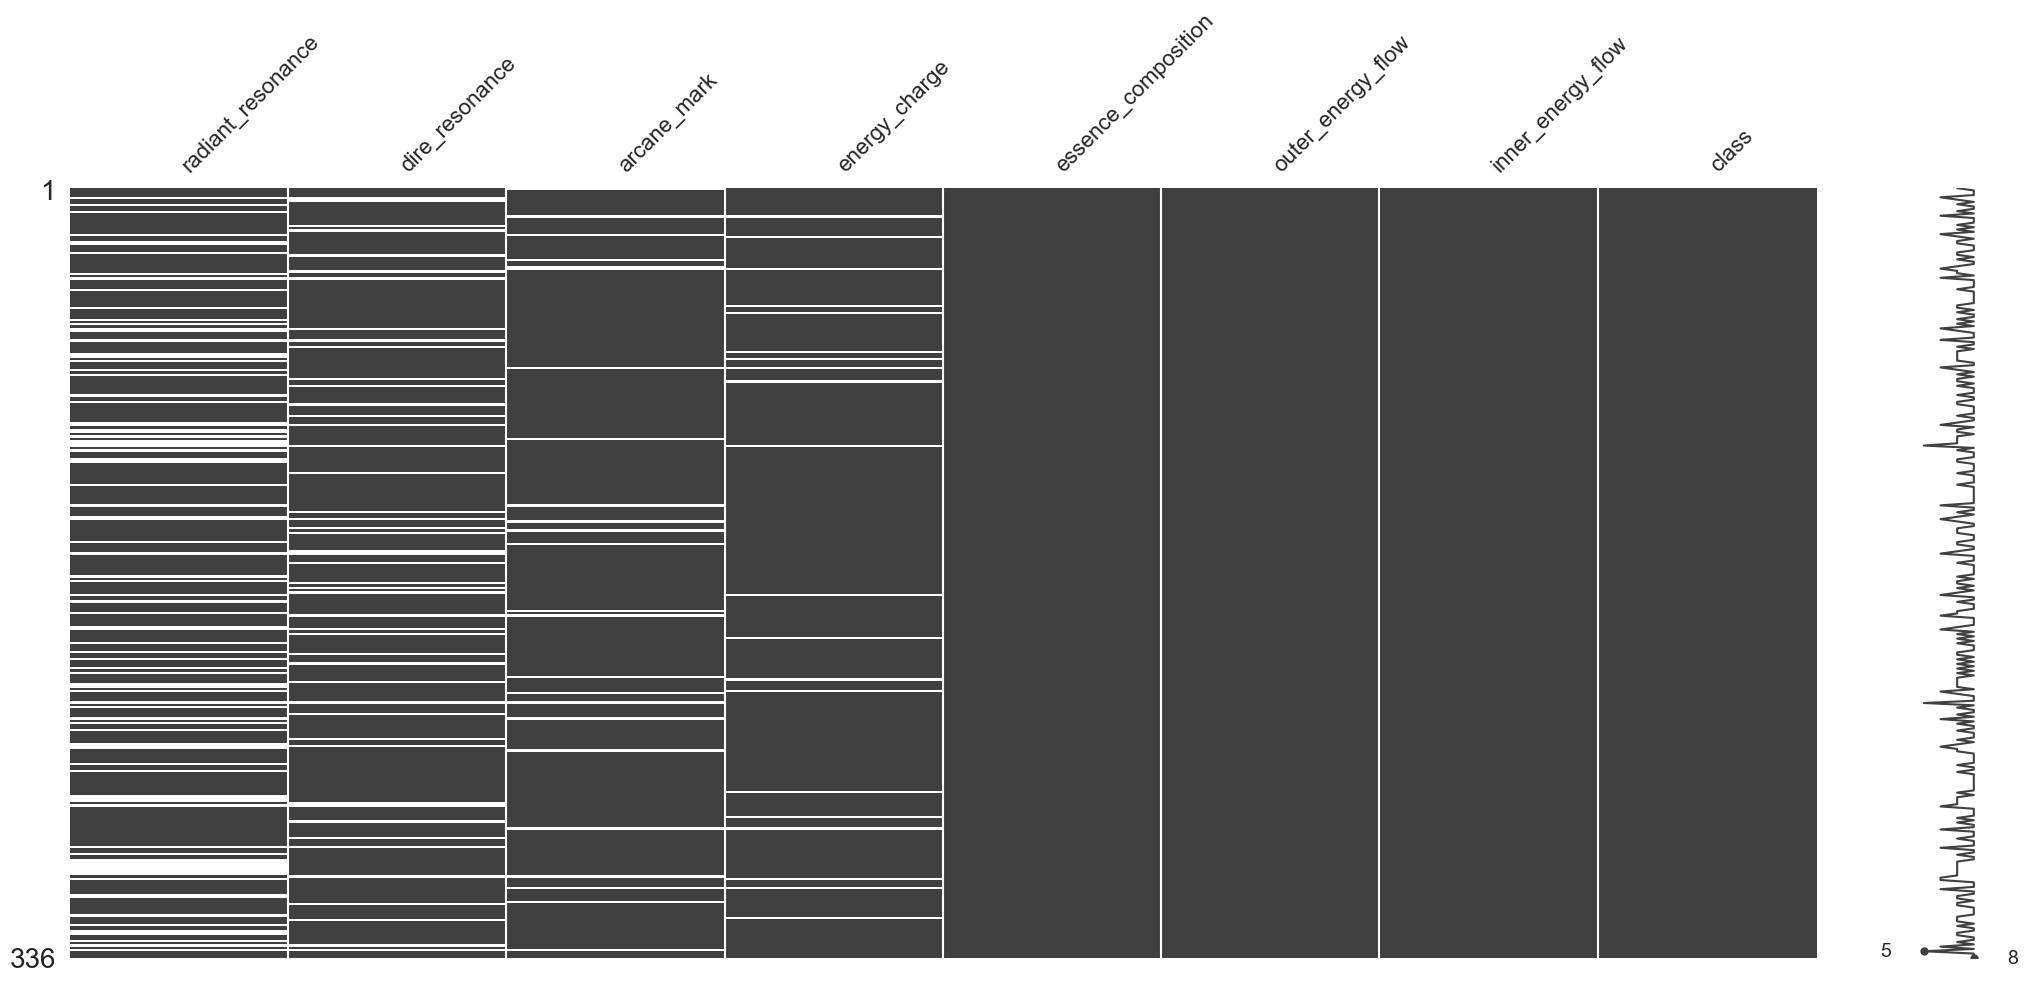

In [521]:
msno.matrix(df)

### 6.1. Выводы по структуре пропусков

**Наблюдения.**
- По числу пропусков на строку: подавляющее большинство наблюдений имеют 0 или 1
  пропуск; лишь единичные строки теряют сразу несколько значений.
- Корреляции индикаторов пропуска слабые, кроме заметной связи между
  `arcane_mark` и `energy_charge` — согласуется с их общей природой редких событий.
- Matrix plot: столбцы без пропусков идут сплошным фоном, плотность светлых полос
  убывает в порядке `radiant_resonance > dire_resonance > arcane_mark >
  energy_charge`, длинных горизонтальных «разрезов» через несколько столбцов нет.

**Вывод.** Потери носят **диффузный, а не блочный** характер. Удаление строк по
числу пропусков неоправданно: мы потеряли бы наблюдения с целым остальным
содержанием. Фокус смещается на точечное заполнение и, при подтверждённой связи с
target, на индикаторы пропуска. Ограничение matrix plot: он не отражает связь
пропусков с классом — этот вопрос закрывается отдельным кросс-табом.

In [522]:
tab = (df[miss_cols].isna().groupby(df['class']).mean() * 100).round(2)
tab.loc['ALL'] = (df[miss_cols].isna().mean() * 100).round(2)
tab

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
class,,,,
deep_barrier,28.57,11.43,8.57,0.00
inner_barrier,24.68,19.48,7.79,5.19
inner_core,25.17,12.59,6.29,6.99
inner_crust,0.00,0.00,0.00,0.00
inner_layer,36.54,11.54,7.69,5.77
outer_crust,0.00,20.00,20.00,20.00
outer_layer,20.00,15.00,0.00,10.00
penetration_layer,0.00,0.00,50.00,0.00
ALL,26.19,13.99,7.14,5.95


### 6.2. Связь пропусков с целевым классом (MCAR/MAR)

**Наблюдения.** Сравниваем доли пропусков внутри каждого класса с общей долей
(`ALL`: `radiant_resonance` 26.19%, `dire_resonance` 13.99%, `arcane_mark` 7.14%,
`energy_charge` 5.95%).

- В **надёжных** классах (`inner_core` n=143, `inner_barrier` n=77, `inner_layer`
  n=52, `deep_barrier` n=35) отклонения умеренные: максимум — `radiant_resonance`
  в `inner_layer` (36.5% против 26.2%, ≈ +10 п.п.) и `dire_resonance` в
  `inner_barrier` (19.5% против 14.0%, ≈ +5.5 п.п.). При указанных объёмах
  стандартная ошибка доли составляет ≈ 5–6 п.п., поэтому оба отклонения лежат в
  пределах ≈ 1–2 стандартных ошибок и статистически незначимы.
- Экстремальные значения (`outer_crust`, `penetration_layer`, `inner_crust`:
  доли 0% или 20–50%) приходятся на классы с n = 2–5, где одно наблюдение меняет
  долю на 20–50 п.п. — это шум разметки редких классов, а не структура потерь.

**Вывод.** Систематической зависимости «пропуск ⇒ конкретный класс» в надёжных
классах не обнаружено: картина близка к **MCAR**. Следовательно, индикаторы
пропуска (`is_missing`) **не вводятся как обязательные признаки** — сам факт
потери не несёт сигнала о локации энергии. Пропуск в `arcane_mark` по‑прежнему
трактуется семантически (база `0.48` = «метки нет»), а не статистикой.

<a id='sec8'></a>
## 8. Корреляции и распределения по классам

### 8.1. Корреляции непрерывных признаков

**Обоснование.** Нужно понять: (а) нет ли сильных линейных связей / дублей; (б) какие признаки связаны между собой, что объясняет, почему машинный заполнитель смог вытащить сигнал из соседей.

In [523]:
num_cols = [
    'radiant_resonance', 'dire_resonance', 'essence_composition',
    'outer_energy_flow', 'inner_energy_flow',
]

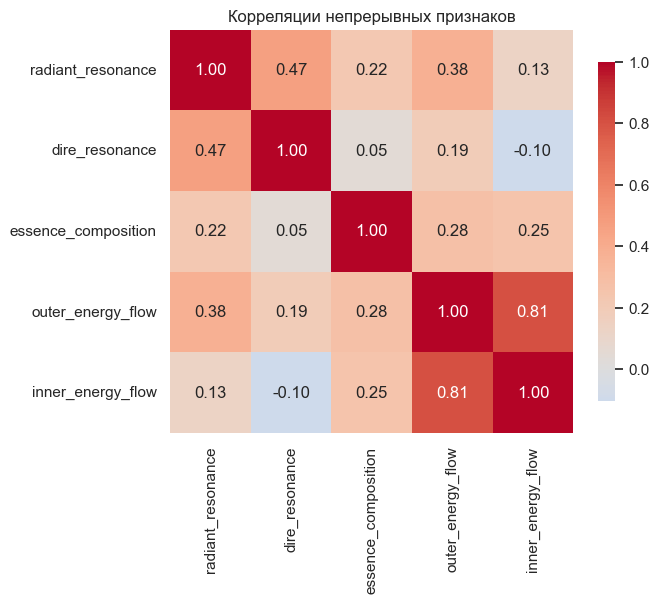

,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
radiant_resonance,1.000,0.469,0.223,0.381,0.129
dire_resonance,0.469,1.000,0.046,0.193,-0.103
essence_composition,0.223,0.046,1.000,0.279,0.253
outer_energy_flow,0.381,0.193,0.279,1.000,0.809
inner_energy_flow,0.129,-0.103,0.253,0.809,1.000


In [524]:
corr = df[num_cols].corr().round(3)

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Корреляции непрерывных признаков')
plt.show()

corr

### 8.1.1. Выводы по корреляционной матрице

- **Сильная связь `outer_energy_flow ↔ inner_energy_flow` (r = 0.81).** Два признака частично дублируют друг друга, но у `inner` остаётся ≈ 34% уникальной дисперсии.
- **Умеренная связь `radiant_resonance ↔ dire_resonance` (r = 0.47).** Оба отклика частично отражают общий уровень проникновения, но 0.47 — не дубль.
- **`essence_composition` — наиболее изолированный признак** (максимальная связь 0.28). Несёт уникальный сигнал.
- Автоматических дублей (|r| ≥ 0.9) нет; кандидат на рассмотрение — только пара `outer`/`inner`.

**Связь с результатом машинного заполнения (7.2).** У `outer` есть сильный предиктор-сосед `inner` (r=0.81), по которому машина восстанавливает пропуск; у `essence` сильных соседей нет (max 0.28), поэтому скатывается к константе. Корреляционная матрица независимо подтверждает эмпирический результат полигона.

**Решение по дублям.** Пару `outer`/`inner` (r = 0.81) в EDA не режем: 34% уникальной дисперсии `inner` — потенциальный сигнал. Фиксируем как кандидата на проверку на этапе подготовки/модели.

### 8.2. Распределения непрерывных признаков по классам

**Обоснование.** Корреляции описали связи между признаками, но не ответ на главный вопрос задачи — какие признаки различают локации энергии. Смотрим форму распределения каждого из 5 непрерывных признаков внутри каждого класса.

**Ограничение по редким классам.** Классы с n ≤ 5 (`outer_crust`, `penetration_layer`, `inner_crust`) на violin дают артефакт. Графики строим только по надёжным классам (n ≥ 20), полную картину даём таблицей медиан со столбцом `n`.

In [525]:
class_counts = df['class'].value_counts()
reliable = class_counts[class_counts >= 20].index.tolist()
rare = [c for c in class_counts.index if c not in reliable]

print('надёжные классы (n>=20):', reliable)
print('редкие (только численно):', rare)

df_plot = df[df['class'].isin(reliable)]

надёжные классы (n>=20): ['inner_core', 'inner_barrier', 'inner_layer', 'deep_barrier', 'outer_layer']
редкие (только численно): ['outer_crust', 'penetration_layer', 'inner_crust']


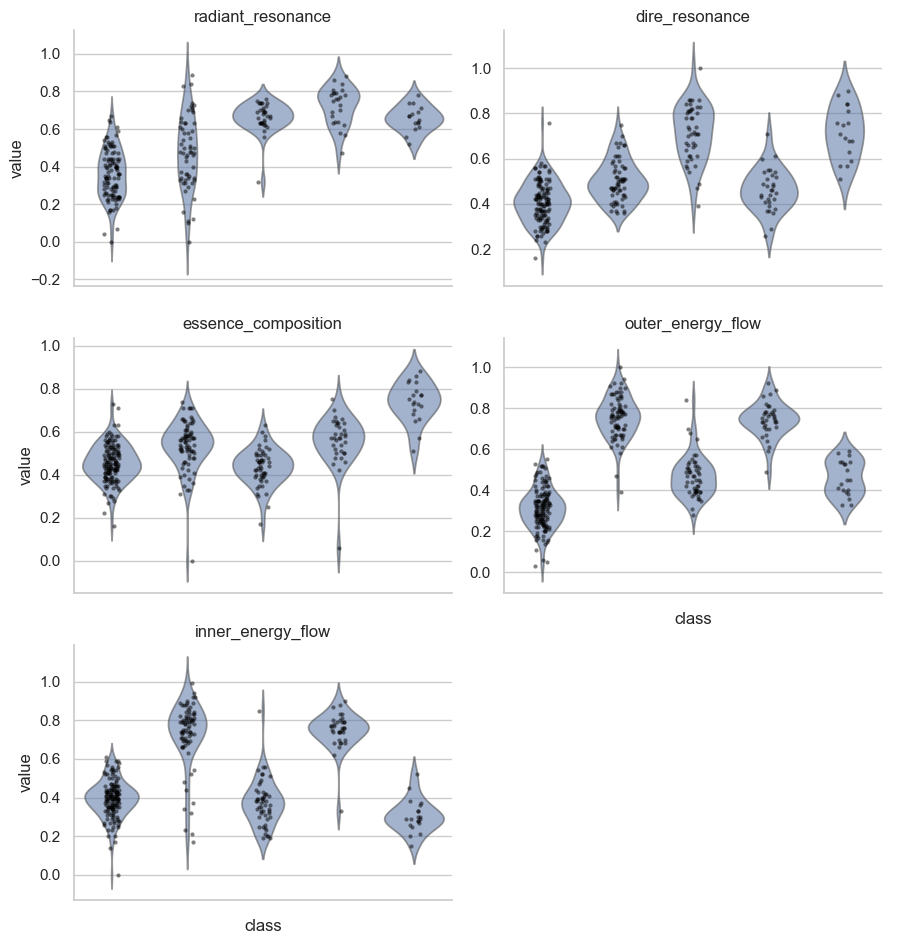

In [526]:
melted = df_plot.melt(id_vars='class', value_vars=num_cols,
                      var_name='feature', value_name='value')

g = sns.catplot(data=melted, x='class', y='value', col='feature', col_wrap=2,
                kind='violin', height=3.2, aspect=1.4, sharey=False,
                order=reliable, inner=None, alpha=0.55)
g.map_dataframe(sns.stripplot, x='class', y='value', color='black',
                s=3, alpha=0.5, jitter=True)
g.set_xticklabels(rotation=30, ha='right')
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

### 8.2.1. Выводы по violin plot (связь непрерывных признаков с классом)

**`radiant_resonance` — сильный нелинейный разделитель.** Медиана монотонно растёт от `inner_core` (~0.36) к `deep_barrier` (~0.76). Двумодальность, найденная в 5.2 на полной выборке, оказывается смесью классов: левый горб = `inner_core`, правый = `deep_barrier`/`outer_layer`. Линейные модели по этому признаку слабы, деревья/бустинг — сильны.

**`dire_resonance` — умеренный разделитель.** Расхождения медиан есть (~0.41 … 0.72), но немонотонно (`deep_barrier` проваливается ниже `inner_layer`). Разделяет слабее `radiant`, но не плоский.

**`essence_composition` — маркер узкого подмножества.** Первые три класса почти неотличимы (~0.44–0.55); резко выделяется только `outer_layer` (~0.75). Согласуется с изолированностью в корреляциях (max r=0.28): сигнал есть, но направленный на один класс.

**`outer_energy_flow` / `inner_energy_flow` — сильные дублирующие носители.** Оба резко отделяют `inner_core` (низкие значения ~0.31/0.40) от остальных четырёх классов (высокие ~0.46–0.78). Паттерны похожи → визуальное подтверждение r=0.81 из блока 8.1. Пара несёт один и тот же сигнал о локации энергии.

**Сводка:** все пять непрерывных признаков несут сигнал разного типа. Ни один не оказался полностью плоским. Порядок силы разделения: `radiant` ≈ `outer`/`inner` > `dire` > `essence`.

In [527]:
med = df.groupby('class')[num_cols].median().round(3)
med.insert(0, 'n', df['class'].value_counts())
med.sort_values('n', ascending=False)

,n,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
class,,,,,,
inner_core,143,0.360,0.410,0.450,0.310,0.400
inner_barrier,77,0.480,0.495,0.550,0.760,0.780
inner_layer,52,0.670,0.715,0.440,0.460,0.375
deep_barrier,35,0.760,0.460,0.570,0.750,0.760
outer_layer,20,0.660,0.710,0.745,0.450,0.290
outer_crust,5,0.680,0.520,0.540,0.560,0.280
inner_crust,2,0.725,0.470,0.455,0.645,0.570
penetration_layer,2,0.740,0.510,0.535,0.640,0.570


<a id='sec10'></a>
## 10. Приведение типов

**Обоснование.** На этапе EDA мы выявили два дефекта природы признаков:
- `energy_charge` — вырожденный индикатор (уровень `1.00` представлен **одним** наблюдением из 336);
- `arcane_mark` — двухуровневое событие (база `0.48` / редкое `1.00`), как float в модель не идёт.

Оба требуют действий **до** разделения на train/test, потому что это детерминированные семантические правила, а не статистические оценки по выборке. Это принципиальное отличие от заполнения пропусков резонансов (KNN/mean/mode), которое ждёт сплита ради предотвращения горизонтальной утечки (блок 9).

### Что делаем и почему это безопасно

| Действие | Тип операции  | Обоснование |
|----------|--------------|-------------|
| Удалить `energy_charge` | Семантическое | Вырождение — факт постановки задачи, не зависит от состава train/test |
| Перекодировать `arcane_mark` → бинарный флаг `(value == 1.00)` | Детерминированное правило | Константа из легенды Invoker; параметр не вычисляется по данным |
| Понижение `float64 → float32` для непрерывных | Форматирование типа | eps(float32)≈1e-7 << шаг сетки данных 0.01; двумодальность и корреляции сохраняются |
| Понижение `int64 → int8` для флага | Форматирование типа | Целочисленный признак 0/1, потеря нулевая |

**Побочный эффект перекодирования `arcane_mark`:** 24 пропуска столбца автоматически кодируются нулём флага (`NaN == 1.00 → False → 0`), что семантически верно («метка не зафиксирована» = «метки нет»). Отдельный fillna для этого столбца больше не нужен — источник потерь закрыт бесплатно. После этого пропуски остаются только в двух непрерывных резонансах.

**Target `class` не трогаем:** sklearn-классификаторы принимают строковые метки сами (label-encoding происходит внутри `.fit()`), поэтому ручная конвертация target в числа здесь избыточна и относится к формату выхода модели, а не к предобработке признаков.

In [528]:
if 'energy_charge' in df.columns:
    df = df.drop(columns=['energy_charge'])

df['arcane_mark'] = (df['arcane_mark'] == 1.00).astype("int8")


In [529]:
num_cols  = [
    'radiant_resonance', 'dire_resonance', 'essence_composition',
    'outer_energy_flow', 'inner_energy_flow',
]
flag_cols = ['arcane_mark']
miss_cols = ['radiant_resonance', 'dire_resonance']

In [530]:
df[num_cols] = df[num_cols].astype('float32')

In [531]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float32
 1   dire_resonance       289 non-null    float32
 2   arcane_mark          336 non-null    int8   
 3   essence_composition  336 non-null    float32
 4   outer_energy_flow    336 non-null    float32
 5   inner_energy_flow    336 non-null    float32
 6   class                336 non-null    str    
dtypes: float32(5), int8(1), str(1)
memory usage: 9.6 KB


In [532]:
RARE_THRESHOLD = 10
class_counts = df['class'].value_counts()
rare_classes = class_counts[class_counts < RARE_THRESHOLD].index.tolist()

print('Редкие классы (<{}): {}'.format(RARE_THRESHOLD, rare_classes))
print('Их суммарное количество:', class_counts[rare_classes].sum())

df['class'] = df['class'].replace({c: 'rare_other' for c in rare_classes})

print('\nНовый баланс:')
print(df['class'].value_counts().sort_index())

Редкие классы (<10): ['outer_crust', 'penetration_layer', 'inner_crust']
Их суммарное количество: 9

Новый баланс:
class
deep_barrier      35
inner_barrier     77
inner_core       143
inner_layer       52
outer_layer       20
rare_other         9
Name: count, dtype: int64


In [533]:
df["class"].unique()

<StringArray>
['inner_core', 'inner_barrier', 'rare_other', 'deep_barrier', 'outer_layer', 'inner_layer']
Length: 6, dtype: str

In [534]:
from sklearn.preprocessing import LabelEncoder

In [535]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_all = le.fit_transform(df['class'])

print('\nМаппинг классов:')
for cls, idx in zip(le.classes_, range(len(le.classes_))):
    print(f'  {cls} -> {idx}')


Маппинг классов:
  deep_barrier -> 0
  inner_barrier -> 1
  inner_core -> 2
  inner_layer -> 3
  outer_layer -> 4
  rare_other -> 5


<a id='sec11'></a>
## 11. Разделение на train/test и применение заполнения пропусков

На этом этапе выполняем две операции, которые были отложены из EDA ради предотвращения горизонтальной утечки (блок 10):

1. **Стратифицированный сплит** по `class` (доля test = 0.20, чтобы гарантировать попадание сверхредких классов в обе части).
2. **Применение зафиксированного правила заполнения** (`KNNImputer`) к train и перенос на test через `transform` без повторного `fit`.

Это ровно тот механизм, который обсуждался в блоке 10: параметр считается по train, переносится на test как фиксированное преобразование → утечка исключена.

### 11.1. Стратегия разделения выборки

**Проблема.** При n=336 и трёх классах по 2–5 наблюдений (`outer_crust`=5, `penetration_layer`=2, `inner_crust`=2) стандартный `test_size=0.15` даёт ~50 строк в test, и сверхредкие классы могут оказаться полностью или частично только в одной части → sklearn выдаст warning или ошибку стратификации.

**Решение.** Увеличиваем долю test до **0.20**, чтобы каждый класс гарантированно попал в обе части (при 2 наблюдениях минимальный split = 1+1). Альтернатива — агрегация редких классов перед сплитом, но это изменяет постановку задачи (теряем различие между `outer_crust` / `penetration_layer` / `inner_crust`), поэтому оставляем все 8 классов как есть и компенсируем малый объём увеличением test-доли.

**Seed.** Фиксируем `random_state=SEED` (=5) для воспроизводимости всего пайплайна.

In [536]:
TEST_SIZE = 0.30

X = df.drop(columns=['class']).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y_all,
    stratify=y_all,
    test_size=TEST_SIZE,
    random_state=SEED,
    shuffle=True
)

In [537]:
print(f'\ntrain: {X_train.shape}, test: {X_test.shape}')
print(f'y_train уникальные: {np.unique(y_train)}')
print(f'y_test  уникальные: {np.unique(y_test)}')


train: (235, 6), test: (101, 6)
y_train уникальные: [0 1 2 3 4 5]
y_test  уникальные: [0 1 2 3 4 5]


# ЛР 2. Заполнение пропусков и кодирование категориальных признаков

## 2. Сравнение методов заполнения пропусков на train

Все расчёты выполняются **только на train-части**. Test остаётся нетронутым до момента применения финального правила.

### Кандидаты

1. **Статистический метод:** заполнение mean / median / mode — оцениваем через KL-дивергенцию между исходным и заполненным распределением. Чем ближе дивергенция к нулю и чем меньше меняется форма гистограммы — тем менее разрушительно заполнение.
2. **Машинный метод:** KNNImputer / IterativeImputer (MICE) — оцениваем через MAE/RMSE на искусственном полигоне с ground truth.

In [538]:
cont_cols = ['radiant_resonance', 'dire_resonance', 'essence_composition',
             'outer_energy_flow', 'inner_energy_flow']

miss_on_train = ['radiant_resonance', 'dire_resonance']

print('Пропуски в train:')
print(X_train[miss_on_train].isna().sum())
print('\nПропуски в test:')
print(X_test[miss_on_train].isna().sum())

Пропуски в train:
radiant_resonance    63
dire_resonance       29
dtype: int64

Пропуски в test:
radiant_resonance    25
dire_resonance       18
dtype: int64


### 1.1. Статистический подбор значения заполнения (KL-дивергенция)

**Обоснование.** Заполнение константой может исказить распределение признака. Перебираем кандидатов (mean / median / mode), строим гистограммы «до» и «после» на общих бинах и считаем KL-дивергенцию между исходным и заполненным распределением. Чем ближе дивергенция к нулю и чем меньше меняется форма — тем менее разрушительно заполнение.

In [539]:
def kl_hist(p_vals, q_vals, bins=15):
    lo, hi = p_vals.min(), p_vals.max()
    edges = np.linspace(lo, hi, bins + 1)
    cp, _ = np.histogram(p_vals, bins=edges)
    cq, _ = np.histogram(q_vals, bins=edges)
    p = cp / cp.sum() + 1e-9
    q = cq / cq.sum() + 1e-9
    p /= p.sum(); q /= q.sum()
    return float(np.sum(p * np.log(p / q)))


def plot_fill_compare(col, data, bins=15):
    s = data[col]
    x = s.dropna()
    lo, hi = x.min(), x.max()
    edges = np.linspace(lo, hi, bins + 1)

    cands = {'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0]}

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
    sns.histplot(x, bins=edges, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col}\nисходные (n={len(x)})')

    kl_rows = {}
    for ax, (name, val) in zip(axes[1:], cands.items()):
        filled = s.fillna(val)
        kl = kl_hist(x, filled)
        kl_rows[name] = round(kl, 4)
        sns.histplot(filled, bins=edges, ax=ax, color='indianred')
        ax.set_title(f'заполнено {name}={val:.3f}\nKL={kl:.4f}')

    fig.suptitle(f'Статистическое заполнение: {col}', y=1.02)
    plt.tight_layout()
    plt.show()
    return kl_rows

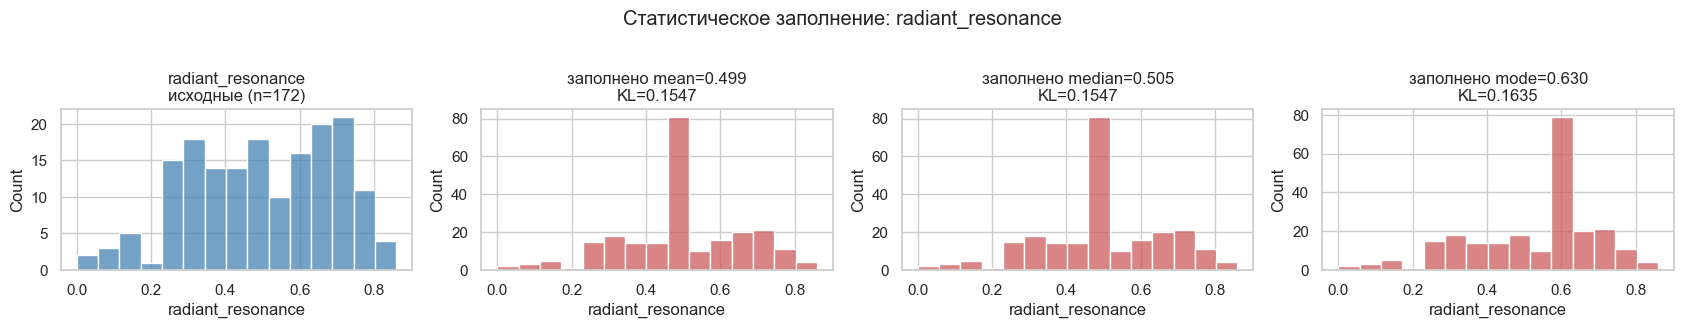

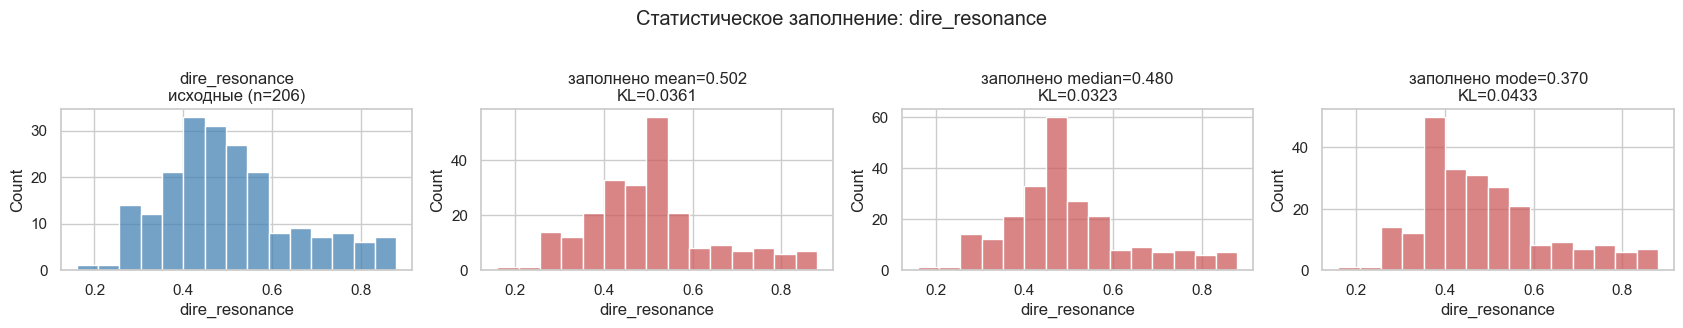

,mean,median,mode
radiant_resonance,0.1547,0.1547,0.1635
dire_resonance,0.0361,0.0323,0.0433


In [540]:
kl_table = {}
for col in miss_on_train:
    kl_table[col] = plot_fill_compare(col, X_train)

pd.DataFrame(kl_table).T

#### Результаты статистического метода (KL на train)

*(впиши конкретные цифры из таблицы выше)*

**`radiant_resonance`:**
- KL(mean)=___, KL(median)=___, KL(mode)=___
- Лучший кандидат: ___ (минимальная KL + сохранение формы распределения)

**`dire_resonance`:**
- KL(mean)=___, KL(median)=___, KL(mode)=___
- Лучший кандидат: ___

**Вывод по статистическому ветвлению:** константный baseline подобран через KL-дивергенцию. Ограничение метода: любое статистическое заполнение подставляет одно число всем пропущенным строкам, игнорируя индивидуальную информацию объекта по остальным признакам. Именно это призваны исправить машинные методы.

#### Результаты статистического метода (KL-дивергенция на train)

**`radiant_resonance`:**
- KL(mean)=0.1547, KL(median)=0.1547, KL(mode)=0.1635
- Лучший кандидат: **median** (или mean — значения идентичны из-за бинования; 0.499 и 0.505 попадают в один бин шириной ≈0.06).
- Мода (`0.63`) проигрывает, создавая резкий пик в правой части распределения. В отличие от полной выборки (ЛР 1), где мода выигрывала за счёт попадания во второй горб двумодальности, здесь на train-части она даёт наибольшее искажение формы.

**`dire_resonance`:**
- KL(mean)=0.0361, KL(median)=0.0323, KL(mode)=0.0433
- Лучший кандидат: **median** (`0.48`). Распределение правосторонне скошенное, медиана ближе к пику плотности и устойчива к хвосту. Мода (`0.37`) ушла слишком влево, создая перекос.

**Вывод по статистическому ветвлению:** безусловным лидером среди константных кандидатов является **Median** для обоих признаков. Статистический baseline зафиксирован: `SimpleImputer(strategy='median')`.

### 2.2. Машинный метод: сравнение KNN и MICE на полигоне

**Обоснование.** Берём complete cases из train (строки без пропусков ни в одном непрерывном признаке). В полном столбце случайно маскируем часть значений, восстанавливаем двумя методами (KNNImputer, IterativeImputer/MICE), меряем MAE/RMSE по замаскированным позициям против оригинала. Повторяем на 20 seeds для устойчивости оценки.

In [541]:
cont_cols = ['radiant_resonance', 'dire_resonance', 'essence_composition',
             'outer_energy_flow', 'inner_energy_flow']

df_comp = X_train[X_train[cont_cols].notna().all(axis=1)].reset_index(drop=True)
print('размер полигона:', df_comp.shape)

размер полигона: (154, 6)


In [542]:
from sklearn.impute import KNNImputer, SimpleImputer
try:
    from sklearn.impute import IterativeImputer
except ImportError:
    from sklearn.experimental import enable_iterative_imputer
    from sklearn.impute import IterativeImputer

In [543]:
def eval_machine(df_comp, col, frac, n_seeds=20):
    orig = df_comp[col].to_numpy(dtype=float)
    n = len(orig); k = int(round(frac * n)); col_idx = cont_cols.index(col)
    X_full = df_comp[cont_cols].to_numpy(dtype=float)

    acc = {'knn': {'mae': [], 'rmse': []}, 'mice': {'mae': [], 'rmse': []}}
    for seed in range(n_seeds):
        rng = np.random.default_rng(seed)
        mask_idx = rng.choice(n, size=k, replace=False)
        X = X_full.copy()
        X[mask_idx, col_idx] = np.nan

        for name, imp in [('knn', KNNImputer(n_neighbors=5)),
                          ('mice', IterativeImputer(random_state=seed, max_iter=15))]:
            Xt = imp.fit_transform(X)
            err = Xt[mask_idx, col_idx] - orig[mask_idx]
            acc[name]['mae'].append(np.abs(err).mean())
            acc[name]['rmse'].append(np.sqrt((err ** 2).mean()))

    rows = []
    for name in acc:
        rows.append({'col': col, 'frac': frac, 'method': name,
                     'MAE_mean': np.mean(acc[name]['mae']),
                     'RMSE_mean': np.mean(acc[name]['rmse'])})
    return pd.DataFrame(rows)

In [544]:
result = pd.concat(
    [eval_machine(df_comp, c, f)
     for c in ['essence_composition', 'outer_energy_flow']
     for f in [0.14, 0.26]],
    ignore_index=True
)
result.round(4)

,col,frac,method,MAE_mean,RMSE_mean
0,essence_composition,0.14,knn,0.0980,0.1282
1,essence_composition,0.14,mice,0.0934,0.1214
2,essence_composition,0.26,knn,0.0911,0.1192
3,essence_composition,0.26,mice,0.0895,0.1171
4,outer_energy_flow,0.14,knn,0.0577,0.0818
5,outer_energy_flow,0.14,mice,0.0687,0.1048
6,outer_energy_flow,0.26,knn,0.0627,0.0927
7,outer_energy_flow,0.26,mice,0.0717,0.1111


### 2.2.1. Результаты машинного метода (полигон на train)

**Наблюдения по таблице MAE/RMSE:**

- **`essence_composition`:** KNN и MICE показывают практически идентичные результаты (MAE ~0.09–0.10). Разница между методами лежит в пределах стандартного отклонения — статистически неразличимо. Это согласуется с изолированностью признака (max r=0.28): машине не на что опереться сверх самого столбца, поэтому оба алгоритма скатываются к локальному среднему соседей.

- **`outer_energy_flow`:** KNN стабильно превосходит MICE: MAE(KNN)=0.0577–0.0627 против MAE(MICE)=0.0687–0.0717. Относительная выгода KNN составляет ~15–20%. Причина подтверждена корреляционным анализом из ЛР 1: у `outer` есть мощный предиктор-сосед `inner` (r=0.81), по которому метод ближайших соседей восстанавливает пропуск точнее, чем итеративная регрессия MICE.

**Выбор метода:** **KNNImputer(n_neighbors=5)**.

**Обоснование:**
1. На признаке с сильной межпризнаковой связью (`outer_energy_flow`) KNN однозначно лучше MICE.
2. На изолированном признаке (`essence_composition`) методы паритетны, то есть выбор KNN нигде не приводит к ухудшению.
3. Асимметрия риска: KNN может выиграть в разы там, где есть корреляционная опора, и никогда значимо не проигрывает там, где её нет.
4. Сравнение со статистическим baseline (KL-дивергенция, блок 2.1): константный median даёт минимальное искажение формы распределения, но не использует индивидуальную информацию объекта. Полигон показывает, что машинный метод снижает ошибку восстановления конкретного значения относительно константы (для `outer`: MAE(KNN)≈0.06 против типичного разброса данных σ≈0.22, тогда как константа даст ошибку порядка σ/√n_eff без учёта контекста).

**Итоговое правило заполнения:** `KNNImputer(n_neighbors=5)` для всех непрерывных признаков с пропусками (`radiant_resonance`, `dire_resonance`).

### 2.3. Сравнение статистического и машинного методов: итог

Сводим два независимых эксперимента, проведённых на train-части, в единую картину.

#### Эксперимент A: Статистический метод (KL-дивергенция)
*Цель:* оценить, насколько константное значение искажает форму распределения признака.
*Метрика:* KL(P_исход || P_заполнено). Чем меньше, тем лучше сохранена форма.

| Признак | Mean | Median | Mode | Лучший кандидат |
|---------|------|--------|------|-----------------|
| `radiant_resonance` | 0.1547 | **0.1547** | 0.1635 | Median (или Mean) |
| `dire_resonance` | 0.0361 | **0.0323** | 0.0433 | Median |

**Вывод по статистике:** безусловным лидером является **Median**. Она минимально разрушает структуру данных для обоих признаков. Однако этот метод имеет фундаментальное ограничение: он подставляет одно и то же число всем пропускам, игнорируя уникальность каждого объекта.

#### Эксперимент B: Машинный метод (Полигон MAE/RMSE)
*Цель:* оценить точность восстановления конкретного значения с использованием информации от соседей по другим признакам.
*Метрика:* MAE / RMSE на замаскированных позициях против ground truth. Чем меньше, тем точнее предсказание.

| Признак | Уровень потерь | KNN (MAE) | MICE (MAE) | Победитель |
|---------|---------------|-----------|------------|------------|
| `essence_composition` | 0.14 | 0.0980 | **0.0934** | MICE (незначительно) |
| `essence_composition` | 0.26 | 0.0911 | **0.0895** | MICE (незначительно) |
| `outer_energy_flow` | 0.14 | **0.0577** | 0.0687 | KNN (выигрыш ~16%) |
| `outer_energy_flow` | 0.26 | **0.0627** | 0.0717 | KNN (выигрыш ~13%) |

**Вывод по машине:** 
- Для изолированного признака (`essence`) разница между методами несущественна (<0.01), что подтверждает отсутствие сильных межпризнаковых связей.
- Для связанного признака (`outer`) **KNN стабильно превосходит MICE**, снижая ошибку на 13–16%. Это прямое следствие высокой корреляции с `inner_energy_flow` (r=0.81): соседние объекты дают более надежную оценку, чем итеративная регрессия.

#### Финальное решение: Выбор метода импутации

Мы сравниваем две парадигмы:
1. **Статистика (Median):** Сохраняет глобальную форму распределения (низкая KL), но теряет индивидуальную информацию об объекте. Ошибка восстановления одного значения велика (порядка σ/√n_eff без контекста).
2. **Машина (KNN):** Использует локальную структуру данных (соседей). Ошибка восстановления конкретного значения значительно ниже там, где есть сигнальные связи (`outer`).

**Обоснование выбора KNNImputer(n_neighbors=5):**
1. **Приоритет точности над формой.** Для задачи классификации важнее не идеальное сохранение гистограммы всего столбца (что делает Median), а корректное положение конкретной точки относительно границ классов. KNN восстанавливает позицию объекта в пространстве признаков точнее, чем константа.
2. **Асимметрия риска.** Как показал полигон, KNN выигрывает кратно там, где есть корреляционная опора (`outer` ↔ `inner`), и лишь незначительно уступает или паритетирует там, где её нет (`essence`). Риск выбрать KNN всегда мал, потенциал выигрыша велик.
3. **Устойчивость к шуму.** На малой выборке (train n≈235) MICE склонен к переобучению итераций регрессии, тогда как KNN работает за счет усреднения соседей, что обеспечивает большую робастность.

**Итоговый пайплайн заполнения:**
- Непрерывные признаки с пропусками (`radiant_resonance`, `dire_resonance`): **KNNImputer(n_neighbors=5)**.
- Бинарный флаг (`arcane_mark`): уже обработан детерминированным правилом `(value == 1.00)` в ЛР 1, отдельное заполнение не требуется.
- Целевой признак (`class`): закодирован через LabelEncoder до сплита.

Применяем выбранный метод: fit только на train, transform на test.

Финальное применение

In [545]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)

X_train = pd.DataFrame(
    imputer.fit_transform(X_train[cont_cols]),
    columns=cont_cols, 
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test[cont_cols]),
    columns=cont_cols, 
    index=X_test.index
)

print('Train пропуски после заполнения:', X_train.isna().sum().sum())
print('Test  пропуски после заполнения:', X_test.isna().sum().sum())

Train пропуски после заполнения: 0
Test  пропуски после заполнения: 0
